<a href="https://colab.research.google.com/github/Kawtharthun/NLP_Lab11/blob/main/Lab_11_Attention_with_RNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [2]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [3]:
df = pd.read_csv("/content/Lab_11_QnA_Dataset_Download.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [4]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [5]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [6]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

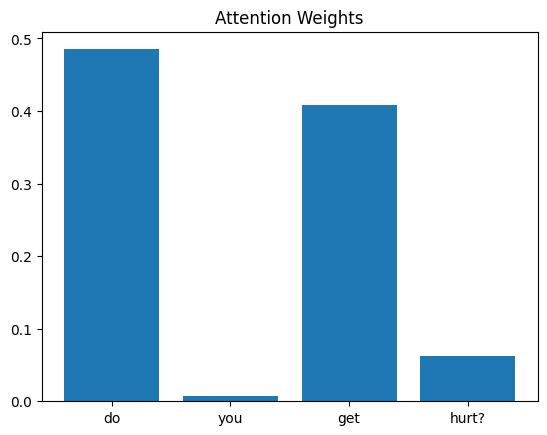

In [7]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

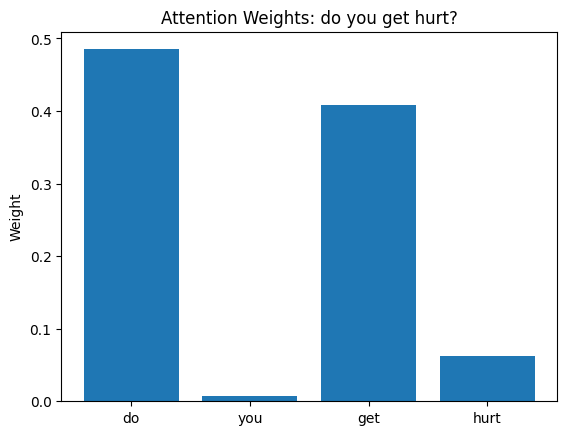

Question: do you get hurt?
Highest-attention word: do
Predicted answer: I don't have a body.
Correct answer: I don't have a body.



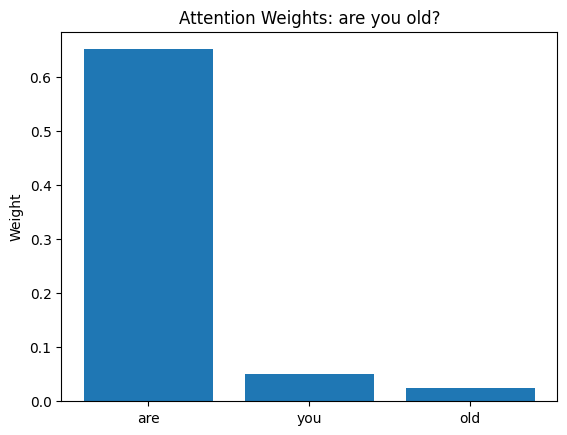

Question: are you old?
Highest-attention word: are
Predicted answer: People created me.
Correct answer: Age doesn't really apply to me.



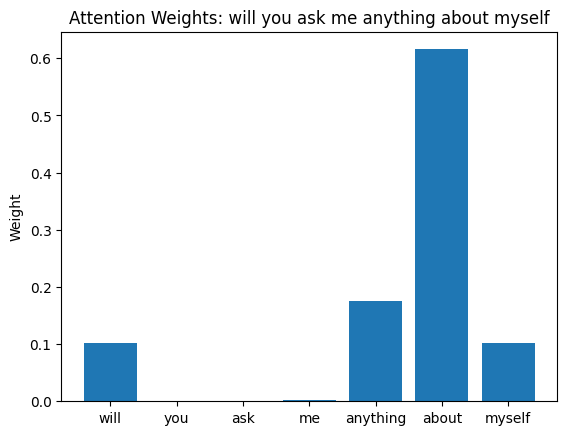

Question: will you ask me anything about myself
Highest-attention word: about
Predicted answer: I'm better at answering questions.
Correct answer: I'm better at answering questions.



In [8]:
def show_attention(i):
    token_ids = X[i][X[i] != 0]
    words = [tokenizer.index_word[t.item()] for t in token_ids]

    with torch.no_grad():
        logits, weights = model(X[i:i+1])

    word_weights = weights[0, :len(words)].tolist()
    top_word = words[word_weights.index(max(word_weights))]
    predicted_id = logits.argmax(1).item()
    predicted_answer = df.loc[df["answer_id"] == predicted_id, "answer"].iloc[0]

    plt.bar(range(len(words)), word_weights)
    plt.xticks(range(len(words)), words)
    plt.title(f"Attention Weights: {df['question'][i]}")
    plt.ylabel("Weight")
    plt.show()

    print("Question:", df["question"][i])
    print("Highest-attention word:", top_word)
    print("Predicted answer:", predicted_answer)
    print("Correct answer:", df["answer"][i])
    print()
    return top_word

for i in [0, 14, 28]:
    show_attention(i)

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

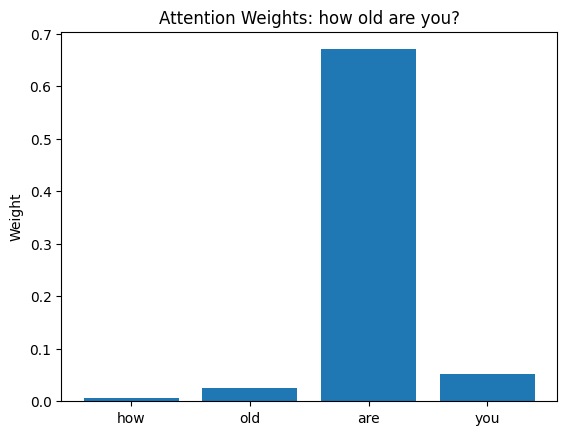

Question: how old are you?
Highest-attention word: are
Predicted answer: People created me.
Correct answer: Age doesn't really apply to me.



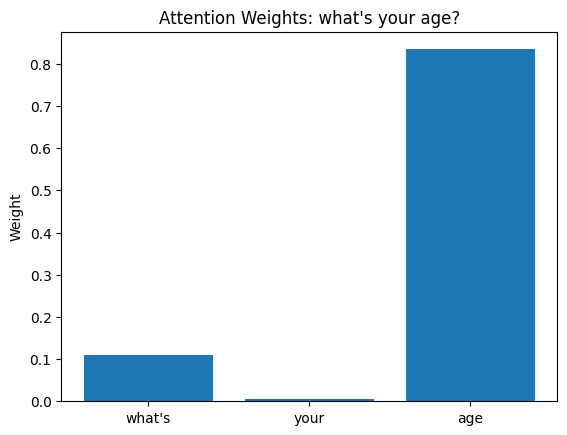

Question: what's your age?
Highest-attention word: age
Predicted answer: Not at all.
Correct answer: Age doesn't really apply to me.

Top word for question 1: are
Top word for question 2: age


In [9]:
q1, q2 = 24, 20  # "how old are you?" and "what's your age?"

top1 = show_attention(q1)
top2 = show_attention(q2)

print("Top word for question 1:", top1)
print("Top word for question 2:", top2)